In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

pd.set_option("display.max_columns",None)

In [5]:
df = pd.read_csv(
    "../data/raw/logistics_shipments.csv"
)

df.head()

,shipment_id,booking_datetime,dispatch_datetime,expected_delivery_datetime,actual_delivery_datetime,origin_city,destination_city,distance_km,package_type,vehicle_type,vehicle_speed_kmph,shipment_weight_kg,weather,traffic_level,route_type,expected_travel_hours,delivery_cost,delay_minutes,delayed
0,SHP0000001,2026-02-25 21:23:51.516168,2026-02-26 21:23:51.516168,2026-02-28 08:16:10.716168,2026-02-28 09:38:10.716168,Hyderabad,Delhi,1569.24,Parcel,Mini Truck,50,9.08,Clear,High,Highway,31.38,2920.95,82,True
1,SHP0000002,2025-07-16 15:06:47.176702,2025-07-17 11:06:47.176702,2025-07-18 19:00:16.776702,2025-07-18 20:09:16.776702,Mumbai,Delhi,1435.12,Parcel,Bike,45,9.46,Clear,High,Local,31.89,2681.06,69,True
2,SHP0000003,2025-10-15 21:16:32.584089,2025-10-15 22:16:32.584089,2025-10-16 16:41:28.584089,2025-10-16 17:12:28.584089,Guwahati,Patna,828.70,Electronics,Van,55,23.65,Storm,Medium,Highway,15.07,1646.26,31,True
3,SHP0000004,2025-09-26 23:20:41.838261,2025-09-27 03:20:41.838261,2025-09-28 17:27:02.638261,2025-09-28 17:33:02.638261,Chennai,Ahmedabad,1714.76,Document,Mini Truck,50,3.89,Fog,Medium,Mixed,34.30,3162.13,6,False
4,SHP0000005,2026-04-02 07:30:24.209876,2026-04-02 20:30:24.209876,2026-04-03 22:04:58.609876,2026-04-03 23:03:58.609876,Jaipur,Mumbai,1150.93,Medicine,Truck,40,5.17,Fog,High,Local,28.77,2152.35,59,True


In [7]:
df.shape

(1000, 19)

In [8]:
print(df.columns)

Index(['shipment_id', 'booking_datetime', 'dispatch_datetime',
       'expected_delivery_datetime', 'actual_delivery_datetime', 'origin_city',
       'destination_city', 'distance_km', 'package_type', 'vehicle_type',
       'vehicle_speed_kmph', 'shipment_weight_kg', 'weather', 'traffic_level',
       'route_type', 'expected_travel_hours', 'delivery_cost', 'delay_minutes',
       'delayed'],
      dtype='str')


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   shipment_id                 1000 non-null   str    
 1   booking_datetime            1000 non-null   str    
 2   dispatch_datetime           1000 non-null   str    
 3   expected_delivery_datetime  1000 non-null   str    
 4   actual_delivery_datetime    1000 non-null   str    
 5   origin_city                 1000 non-null   str    
 6   destination_city            1000 non-null   str    
 7   distance_km                 1000 non-null   float64
 8   package_type                1000 non-null   str    
 9   vehicle_type                1000 non-null   str    
 10  vehicle_speed_kmph          1000 non-null   int64  
 11  shipment_weight_kg          1000 non-null   float64
 12  weather                     1000 non-null   str    
 13  traffic_level               1000 non-null   s

In [10]:
df.describe()

,distance_km,vehicle_speed_kmph,shipment_weight_kg,expected_travel_hours,delivery_cost,delay_minutes
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,1226.932760,47.475000,19.952070,26.198980,2348.287320,33.82800
std,576.537671,5.672879,11.598701,12.744578,1040.587887,31.61661
min,94.160000,40.000000,0.260000,1.880000,322.290000,0.00000
25%,767.080000,40.000000,9.530000,16.060000,1518.572500,3.00000
50%,1192.340000,45.000000,19.645000,25.345000,2290.135000,27.00000
75%,1641.817500,55.000000,30.080000,34.760000,3118.230000,56.00000
max,2607.920000,55.000000,39.960000,62.530000,4891.600000,159.00000


In [11]:
df.describe(include="object")

/var/folders/jd/4m4mxltj489dn4rpxn4vb5c80000gn/T/ipykernel_56257/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,shipment_id,booking_datetime,dispatch_datetime,expected_delivery_datetime,actual_delivery_datetime,origin_city,destination_city,package_type,vehicle_type,weather,traffic_level,route_type
count,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,1000,1000,1000,1000,1000,20,20,6,4,4,3,3
top,SHP0000001,2026-02-25 21:23:51.516168,2026-02-26 21:23:51.516168,2026-02-28 08:16:10.716168,2026-02-28 09:38:10.716168,Patna,Hyderabad,Furniture,Van,Storm,Medium,Highway
freq,1,1,1,1,1,69,64,184,262,263,348,345


In [12]:
df.isnull().sum()

shipment_id                   0
booking_datetime              0
dispatch_datetime             0
expected_delivery_datetime    0
actual_delivery_datetime      0
origin_city                   0
destination_city              0
distance_km                   0
package_type                  0
vehicle_type                  0
vehicle_speed_kmph            0
shipment_weight_kg            0
weather                       0
traffic_level                 0
route_type                    0
expected_travel_hours         0
delivery_cost                 0
delay_minutes                 0
delayed                       0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["delayed"].value_counts()

delayed
False    528
True     472
Name: count, dtype: int64

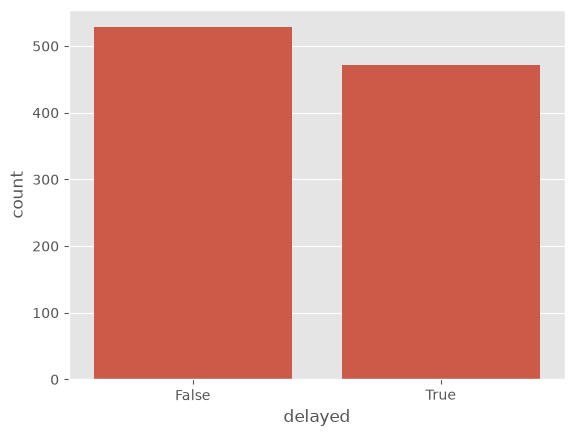

In [15]:
sns.countplot(
    data=df,
    x="delayed"
)

plt.show()

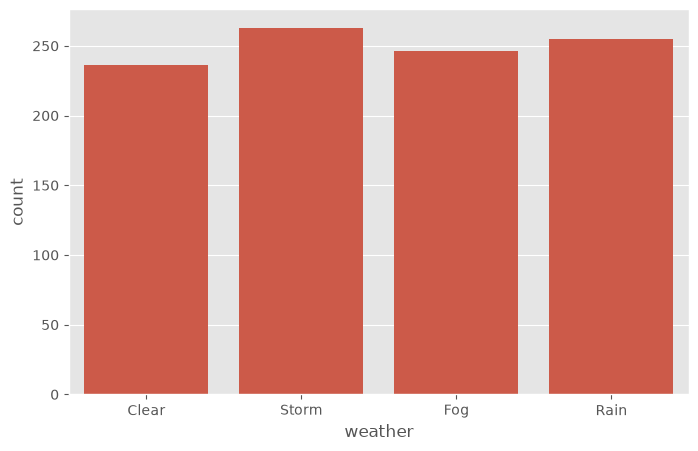

In [16]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="weather"
)

plt.show()

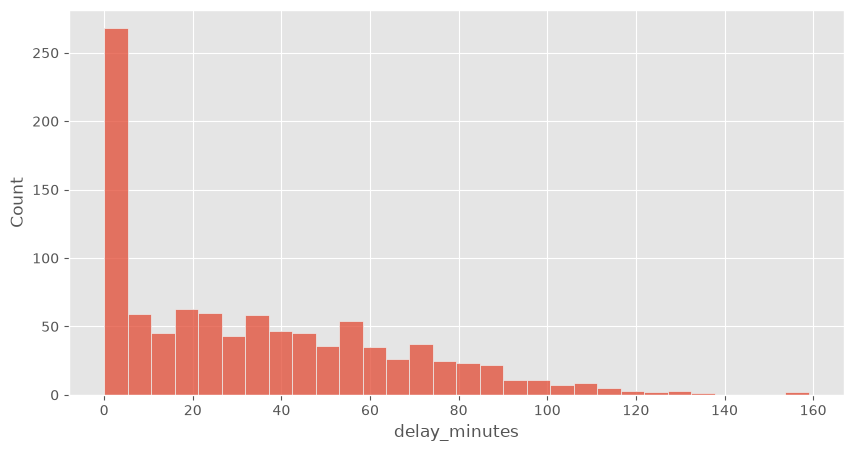

In [18]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["delay_minutes"],
    bins=30
)

plt.show()

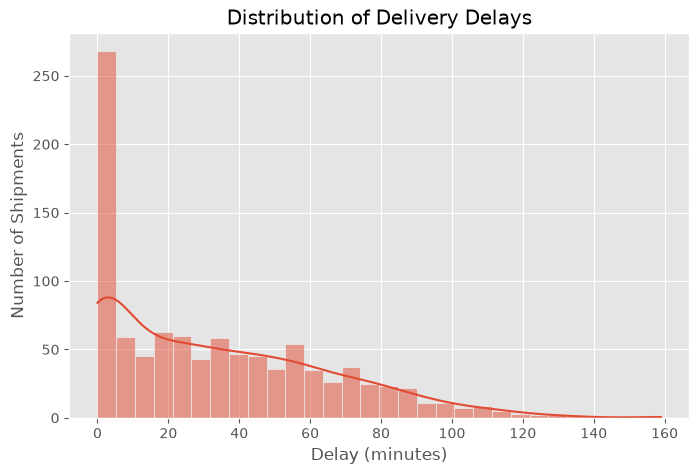

In [20]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="delay_minutes",
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Delays")
plt.xlabel("Delay (minutes)")
plt.ylabel("Number of Shipments")

plt.show()

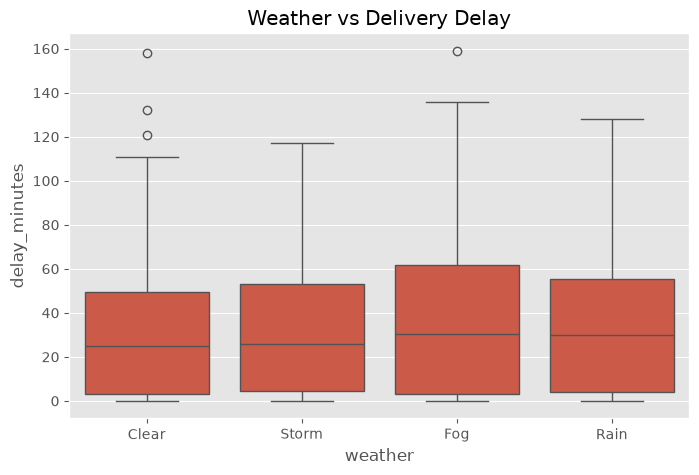

In [21]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="weather",
    y="delay_minutes"
)

plt.title("Weather vs Delivery Delay")

plt.show()

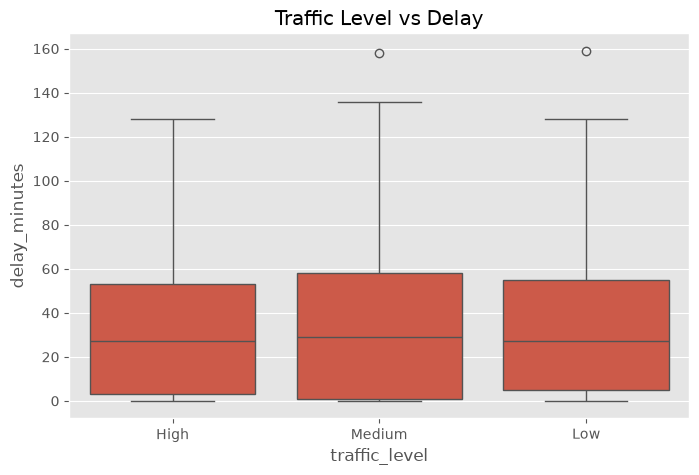

In [22]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="traffic_level",
    y="delay_minutes"
)

plt.title("Traffic Level vs Delay")

plt.show()

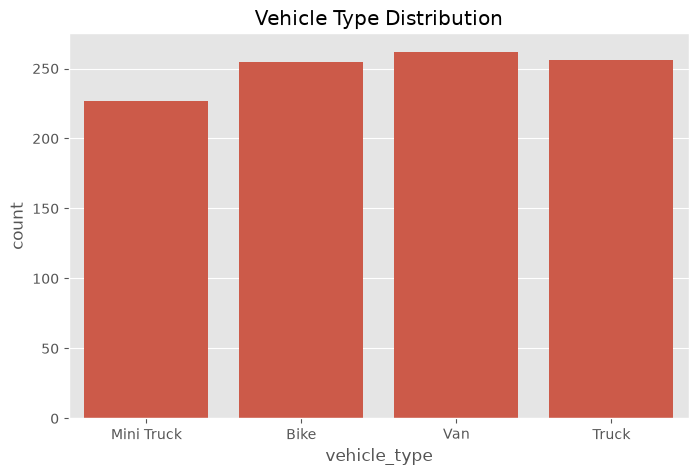

In [23]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="vehicle_type"
)

plt.title("Vehicle Type Distribution")

plt.show()

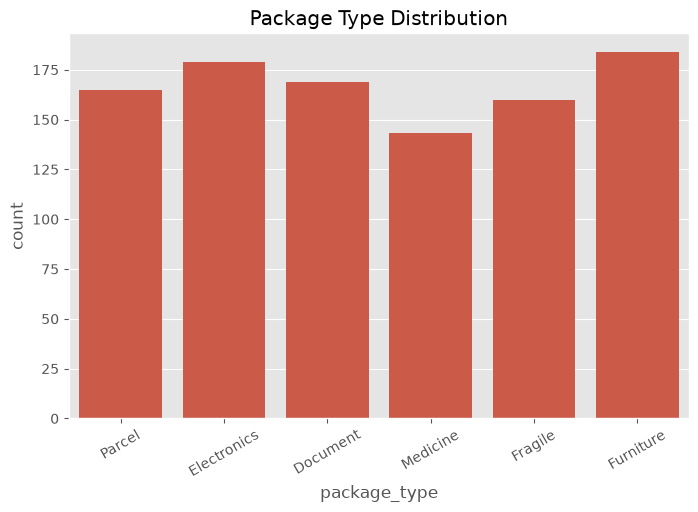

In [24]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="package_type"
)

plt.title("Package Type Distribution")

plt.xticks(rotation=30)

plt.show()

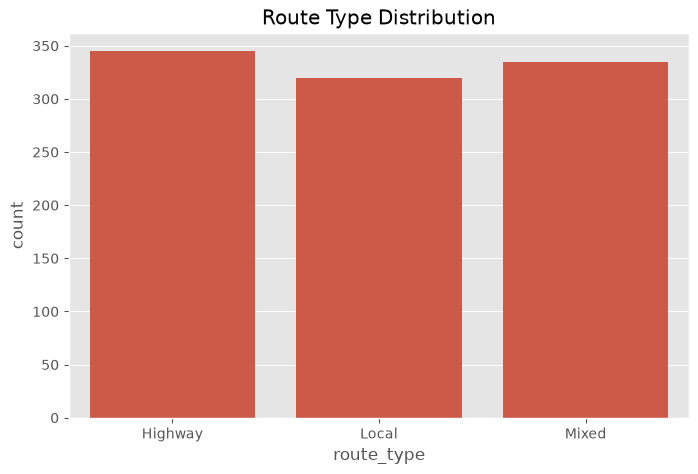

In [25]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="route_type"
)

plt.title("Route Type Distribution")

plt.show()

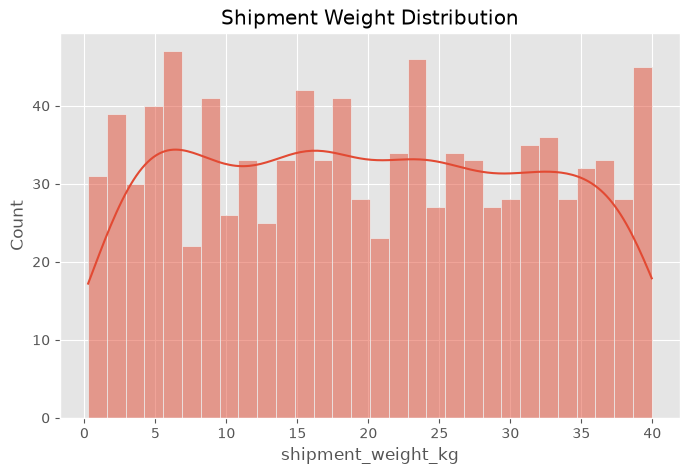

In [26]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["shipment_weight_kg"],
    bins=30,
    kde=True
)

plt.title("Shipment Weight Distribution")

plt.show()

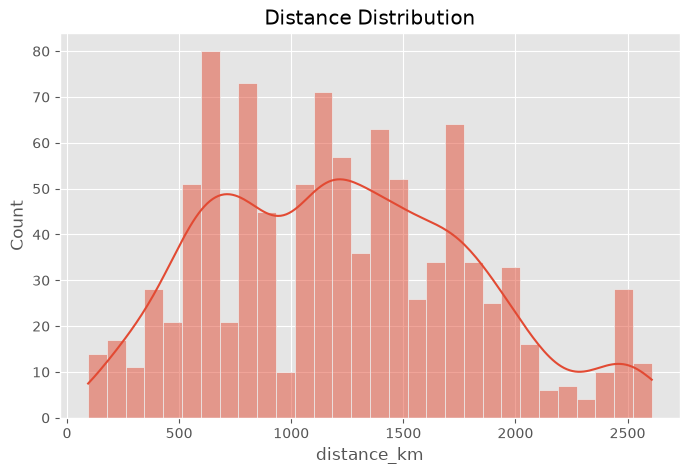

In [27]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["distance_km"],
    bins=30,
    kde=True
)

plt.title("Distance Distribution")

plt.show()

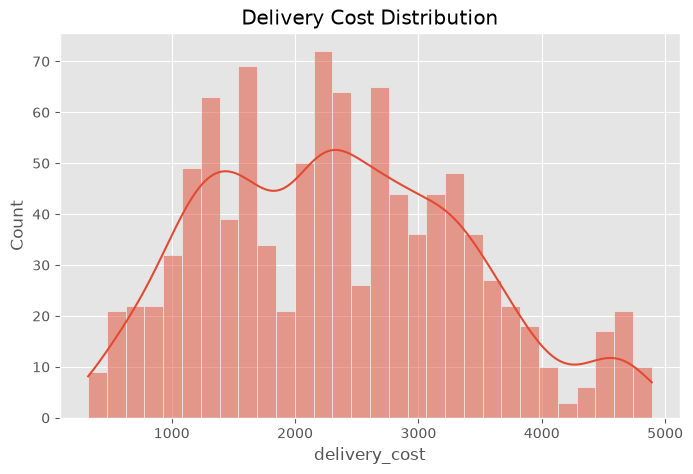

In [28]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["delivery_cost"],
    bins=30,
    kde=True
)

plt.title("Delivery Cost Distribution")

plt.show()

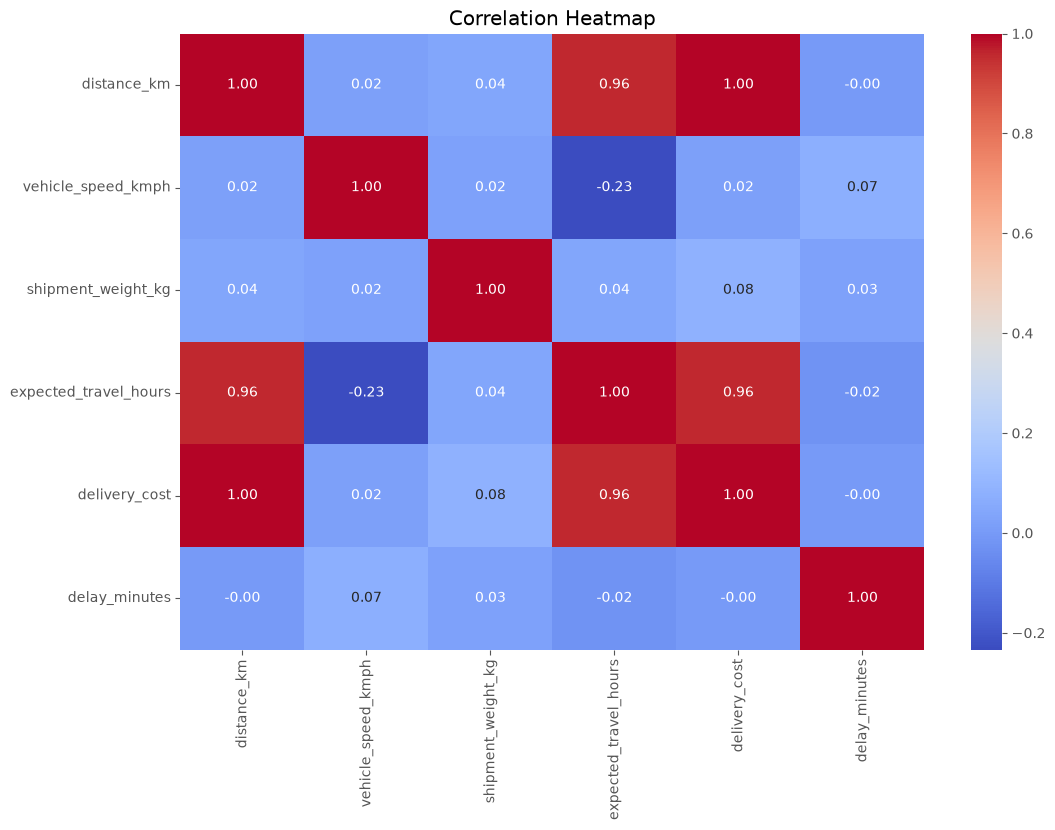

In [29]:
plt.figure(figsize=(12,8))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

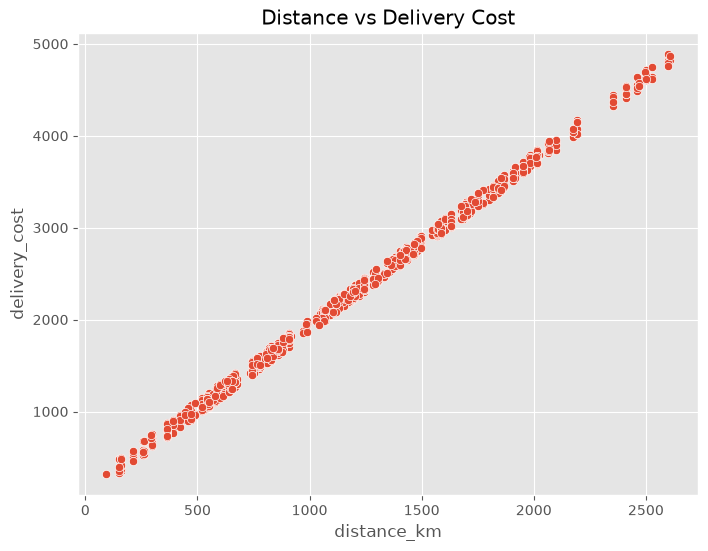

In [30]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="distance_km",
    y="delivery_cost"
)

plt.title("Distance vs Delivery Cost")

plt.show()

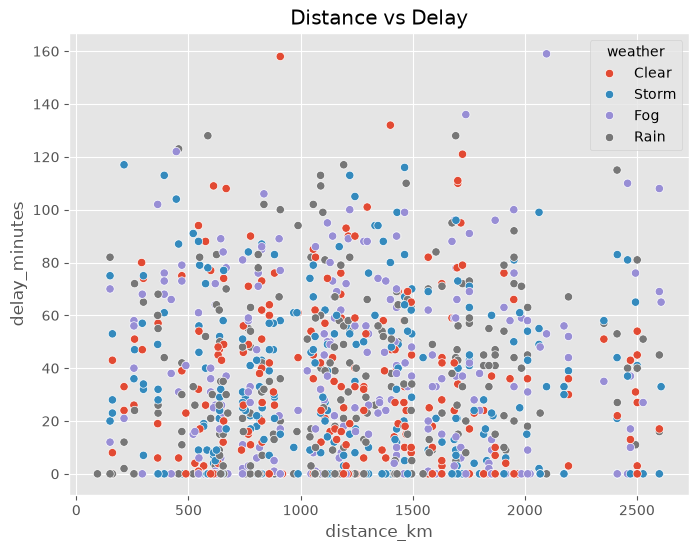

In [31]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="distance_km",
    y="delay_minutes",
    hue="weather"
)

plt.title("Distance vs Delay")

plt.show()